# B3 Parameter Grid Search
6-dimension grid across BOVA11 and PETR4 with train/holdout split. Train ends pre-COVID (Mar 2020 crash excluded). Holdout = 2020-04 to 2025-12.

Backtests run with **cash_investment_mode="risk_free" + yield=0%** so that `sharpe`, `total_return`, `max_drawdown` reflect the pure strangle P&L — no underlying B&H contamination.

In [12]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd().name == "research") else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
sys.path.insert(0, str(ROOT / "src"))
from grid_search import run_grid, enumerate_grid, GRID_DIMS

OUT_DIR = ROOT / "data" / "B3"
RESULTS_PATH = OUT_DIR / "grid_search_results_volfilter.parquet"

In [13]:
GRID = {
    "target_delta": [0.20, 0.25, 0.30],
    "dte_max": [21, 30, 45],
    "profit_target_pct": [0.25, 0.50, 0.75],
    "manage_at_dte": [10, 14, 21],
    "vix_filter": [
        "OFF",
        "25",
        "rv_pct:70",
        "rv_pct:80",
        "rv_pct:90",
        "ivr:30",
        "ivr:50",
    ],
    "defensive_leg_roll": [True, False],
}
combos = enumerate_grid(GRID)
print(f"Valid combos per (market, period): {len(combos)}")

Grid: 1134 raw combos, 882 after validity filter (252 dropped)
Valid combos per (market, period): 882


In [14]:
RUNS = [
    ("train", "bova11", "2020-04-01", "2023-12-31"),
    ("holdout", "bova11", "2024-01-01", "2025-12-31"),
    ("train", "petr4", "2020-04-01", "2023-12-31"),
    ("holdout", "petr4", "2024-01-01", "2025-12-31"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2020-04-01', '2023-12-31')
('holdout', 'bova11', '2024-01-01', '2025-12-31')
('train', 'petr4', '2020-04-01', '2023-12-31')
('holdout', 'petr4', '2024-01-01', '2025-12-31')


In [15]:
df = run_grid(GRID, RUNS, n_workers=-1, output_path=RESULTS_PATH)
print(f"Saved {len(df)} rows to {RESULTS_PATH}")

Grid: 1134 raw combos, 882 after validity filter (252 dropped)
Dispatching 882 tasks for bova11 (train)...


bova11-train:   0%|          | 0/882 [00:00<?, ?it/s]

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
Market

bova11-train:   0%|          | 1/882 [00:00<06:05,  2.41it/s]]

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
Market

...

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)


petr4-holdout:  99%|█████████▉| 873/882 [00:46<00:00,  9.55it/s].65day/s] 

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)


petr4-holdout: 100%|██████████| 882/882 [00:47<00:00, 18.73it/s]


Checkpoint saved: 3528 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/grid_search_results_volfilter.parquet
Summary: 3528 runs total — 0 errors, 535 with n_trades < 50, 0 invalid (manage_at_dte >= dte_min)
Saved 3528 rows to /Users/oliversteiner/Documents/code/options-backtest/data/B3/grid_search_results_volfilter.parquet


In [16]:
df = pd.read_parquet(RESULTS_PATH)
print(df.shape)
df.head()

(3528, 27)


,target_delta,dte_max,profit_target_pct,manage_at_dte,vix_filter,defensive_leg_roll,market,period_label,start_date,end_date,...,underlying_return,underlying_sharpe,alpha_vs_bh,alpha_sharpe,n_chains,n_rolls_total,avg_rolls_per_chain,max_rolls_per_chain,chain_length_dist,error
0,0.2,21,0.25,10,OFF,True,bova11,train,2020-04-01,2023-12-31,...,0.912438,0.518607,-0.945650,-0.945365,87,21,0.241379,1,"{0: 66, 1: 21}",None
1,0.2,21,0.25,10,OFF,False,bova11,train,2020-04-01,2023-12-31,...,0.912438,0.518607,-0.916952,-0.908627,87,21,0.241379,1,"{0: 66, 1: 21}",None
2,0.2,21,0.25,10,25,True,bova11,train,2020-04-01,2023-12-31,...,0.912438,0.518607,-0.959972,-0.963787,54,6,0.111111,1,"{0: 48, 1: 6}",None
3,0.2,21,0.25,10,25,False,bova11,train,2020-04-01,2023-12-31,...,0.912438,0.518607,-0.941116,-0.940384,54,8,0.148148,1,"{0: 46, 1: 8}",None
4,0.2,21,0.25,10,rv_pct:70,True,bova11,train,2020-04-01,2023-12-31,...,0.912438,0.518607,-0.950774,-0.949066,76,13,0.171053,1,"{0: 63, 1: 13}",None


In [17]:
print("Total rows:", len(df))
print("By market \u00d7 period:")
print(df.groupby(["market", "period_label"]).size())
print("\nFailures:", (df["error"].notna()).sum())
print("Underpowered (n_trades < 100):", (df["n_trades"] < 100).sum())

clean = df[df["error"].isna()]
print("\n=== Strangle Sharpe (pure options, no B&H) ===")
print(
    clean.groupby(["market", "period_label"])["sharpe"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

print("\n=== Alpha Sharpe (residual vs B&H) ===")
print(
    clean.groupby(["market", "period_label"])["alpha_sharpe"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

print("\n=== Alpha vs B&H (return delta) ===")
print(
    clean.groupby(["market", "period_label"])["alpha_vs_bh"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

if (df["error"].notna()).sum() > 0:
    print(f"\nWARNING: {df['error'].notna().sum()} failed rows")
    failures = df[df["error"].notna()]
    for _, r in failures.iterrows():
        print(
            f"  [{r['market']}/{r['period_label']}]"
            f" vix={r['vix_filter']} d={r['target_delta']}"
            f" dte={r['dte_max']}: {str(r['error'])[:200]}"
        )

Total rows: 3528
By market × period:
market  period_label
bova11  holdout         882
        train           882
petr4   holdout         882
        train           882
dtype: int64

Failures: 0
Underpowered (n_trades < 100): 1719

=== Strangle Sharpe (pure options, no B&H) ===
                         mean       std       min       max
market period_label                                        
bova11 holdout      -0.662403  0.566320 -3.212845  0.425584
       train        -0.105383  0.435080 -2.040386  0.960025
petr4  holdout      -0.923090  0.710607 -3.589383  0.019518
       train        -0.234758  0.789481 -4.434191  1.734916

=== Alpha Sharpe (residual vs B&H) ===
                         mean       std       min       max
market period_label                                        
bova11 holdout      -0.894939  0.111241 -1.266992 -0.556605
       train        -0.941081  0.095227 -1.258959 -0.508972
petr4  holdout       0.153323  0.208396 -0.777688  0.290920
       train        

## Verification

Checks from the plan (docs/B3_GRID_SEARCH_PLAN.md:241-247).

In [18]:
from grid_search import enumerate_grid, GRID_DIMS, DTE_MIN_BY_DTE_MAX

print("Check 1: self-equivalence — see scripts/grid_search.py output")

invalid = df[
    (df["manage_at_dte"] >= df["dte_max"].map(DTE_MIN_BY_DTE_MAX)) & df["error"].isna()
]
assert len(invalid) == 0, f"{len(invalid)} rows violate manage_at_dte < dte_min!"
print(f"Check 2: validity filter — {len(invalid)} post-run violations (expect 0)")

print("Check 3: n\u003c100 — see sanity checks output above")

for mkt in ["bova11", "petr4"]:
    train = df.query(
        "period_label=='train' and market==@mkt and error.isna()", engine="python"
    )
    hold = df.query(
        "period_label=='holdout' and market==@mkt and error.isna()", engine="python"
    )
    j = train.merge(hold, on=GRID_DIMS, suffixes=("_t", "_h"))
    print(
        f"Check 4: {mkt.upper()} — {len(j)}/{len(train)} train configs matched in holdout"
    )
    if len(j) < len(train):
        print(f"  WARNING: {len(train) - len(j)} train configs missing!")

combos2 = enumerate_grid(GRID)
n_valid = df.groupby(["market", "period_label"]).size().unique()
print(f"Check 5: valid combos = {len(combos2)}, rows per period = {n_valid.tolist()}")
assert all(c == len(combos2) for c in n_valid), "diagonal size mismatch"

Check 1: self-equivalence — see scripts/grid_search.py output
Check 2: validity filter — 0 post-run violations (expect 0)
Check 3: n<100 — see sanity checks output above
Check 4: BOVA11 — 882/882 train configs matched in holdout
Check 4: PETR4 — 882/882 train configs matched in holdout
Grid: 1134 raw combos, 882 after validity filter (252 dropped)
Check 5: valid combos = 882, rows per period = [882]


## Heatmap (a) — Sharpe by target_delta × dte_max

Sharpe = pure strangle (risk-free cash, zero yield).

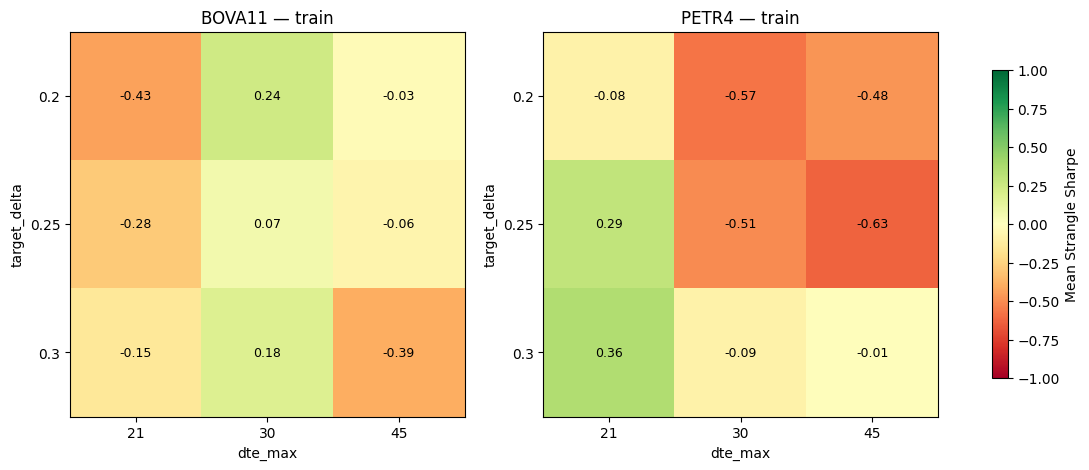

In [19]:
def heatmap(ax, sub, x, y, title, metric="sharpe"):
    pivot = sub.pivot_table(values=metric, index=y, columns=x, aggfunc="mean")
    im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(title)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            ax.text(
                j,
                i,
                f"{v:.2f}" if pd.notna(v) else "n/a",
                ha="center",
                va="center",
                color="black",
                fontsize=9,
            )
    return im


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    sub = df.query(
        "period_label == 'train' and market == @mkt and error.isna()", engine="python"
    )
    im = heatmap(ax, sub, "dte_max", "target_delta", f"{mkt.upper()} \u2014 train")
fig.colorbar(im, ax=axes, label="Mean Strangle Sharpe", shrink=0.8)
plt.savefig(OUT_DIR / "grid_heatmap_delta_dte.png", dpi=120, bbox_inches="tight")
plt.show()

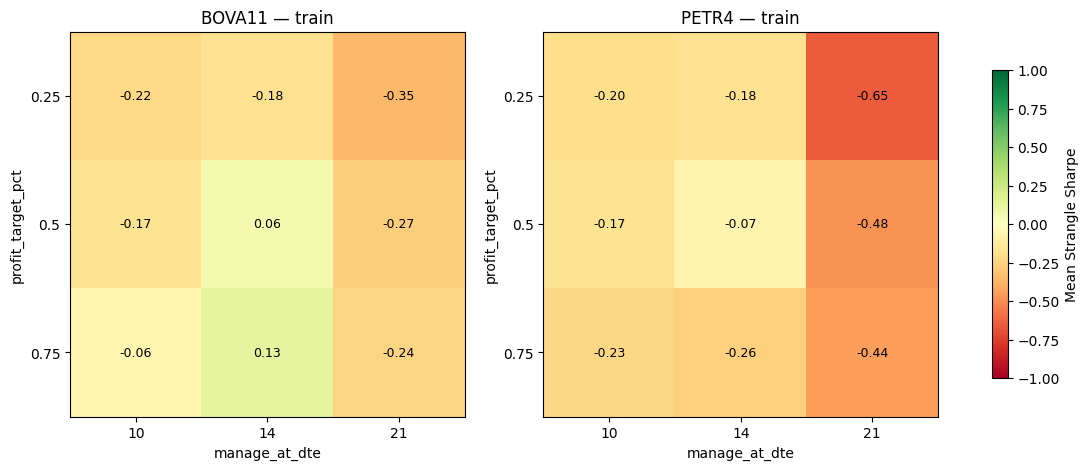

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    sub = df.query(
        "period_label == 'train' and market == @mkt and error.isna()", engine="python"
    )
    im = heatmap(
        ax, sub, "manage_at_dte", "profit_target_pct", f"{mkt.upper()} \u2014 train"
    )
fig.colorbar(im, ax=axes, label="Mean Strangle Sharpe", shrink=0.8)
plt.savefig(OUT_DIR / "grid_heatmap_profit_manage.png", dpi=120, bbox_inches="tight")
plt.show()

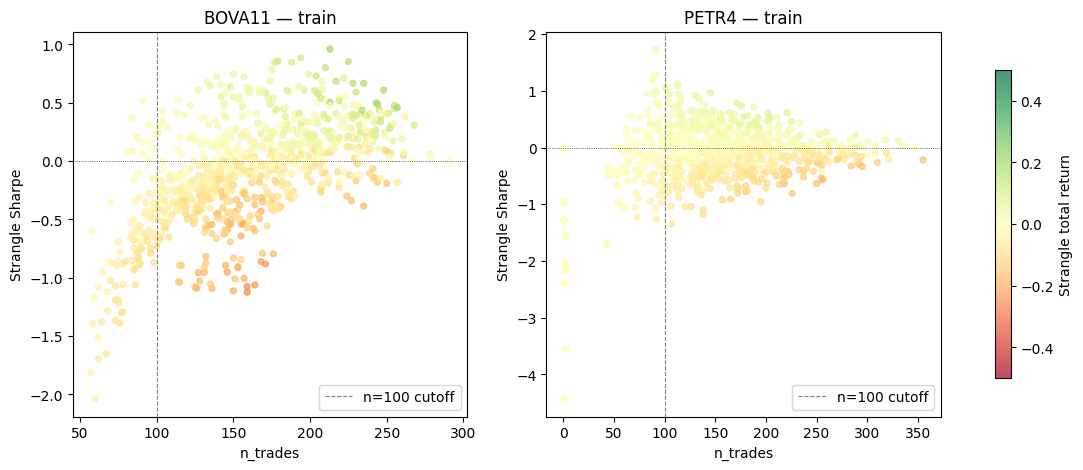

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    sub = df.query(
        "period_label == 'train' and market == @mkt and error.isna()", engine="python"
    )
    sc = ax.scatter(
        sub["n_trades"],
        sub["sharpe"],
        c=sub["total_return"],
        cmap="RdYlGn",
        vmin=-0.5,
        vmax=0.5,
        s=18,
        alpha=0.7,
    )
    ax.axvline(100, ls="--", c="grey", lw=0.8, label="n=100 cutoff")
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.set_xlabel("n_trades")
    ax.set_ylabel("Strangle Sharpe")
    ax.set_title(f"{mkt.upper()} \u2014 train")
    ax.legend(loc="lower right")
fig.colorbar(sc, ax=axes, label="Strangle total return", shrink=0.8)
plt.savefig(OUT_DIR / "grid_scatter_ntrades_sharpe.png", dpi=120, bbox_inches="tight")
plt.show()


=== BOVA11 top-10 by train sharpe (n_trades>=100) ===
  sharpe  alpha_sharpe  alpha_vs_bh  total_return   calmar  n_trades  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll
0.960025     -0.677324    -0.705767      0.206670 1.056016       213          0.25       30               0.75             14  rv_pct:70               False
0.885535     -0.783538    -0.800299      0.112138 0.963109       194          0.20       30               0.50             10        OFF               False
0.856221     -0.755092    -0.781919      0.130518 0.513632       179          0.30       30               0.50             14  rv_pct:70               False
0.853209     -0.732956    -0.749909      0.162528 0.641475       225          0.20       30               0.75             14  rv_pct:80               False
0.847628     -0.793492    -0.809424      0.103013 0.887471       188          0.20       30               0.50             10  rv_pct:90               False
0.8

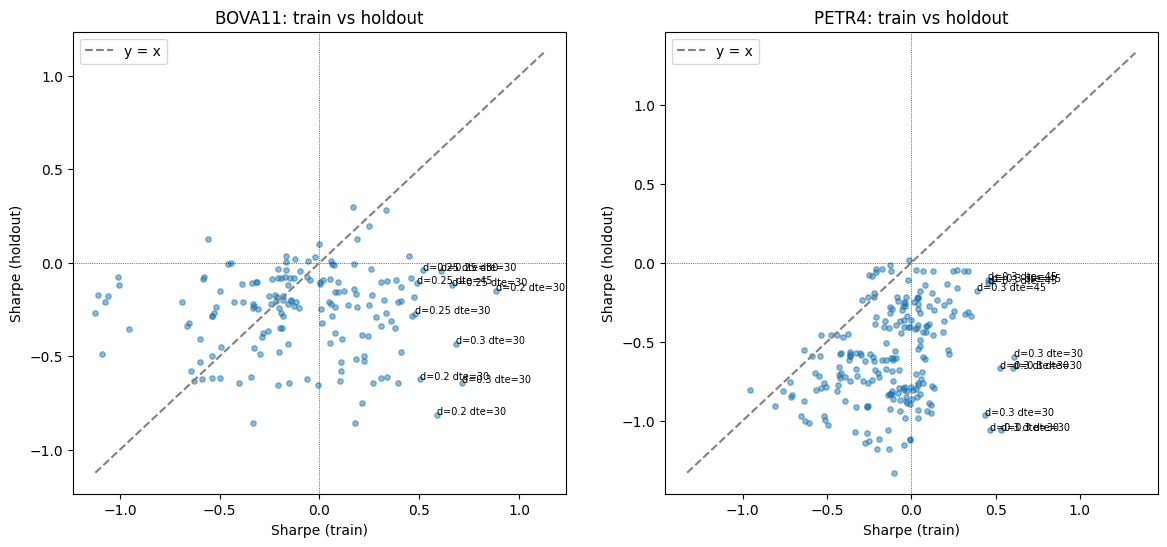

In [22]:
COLS = [
    "sharpe",
    "alpha_sharpe",
    "alpha_vs_bh",
    "total_return",
    "calmar",
    "n_trades",
] + GRID_DIMS

for mkt in ["bova11", "petr4"]:
    print(f"\n=== {mkt.upper()} top-10 by train sharpe (n_trades>=100) ===")
    top = df.query(
        "period_label=='train' and market==@mkt and error.isna() and n_trades>=100",
        engine="python",
    ).nlargest(10, "sharpe")[COLS]
    print(top.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    train = df.query(
        "period_label=='train' and market==@mkt and error.isna() and n_trades>=100",
        engine="python",
    )
    hold = df.query(
        "period_label=='holdout' and market==@mkt and error.isna() and n_trades>=100",
        engine="python",
    )
    j = train.merge(hold, on=GRID_DIMS, suffixes=("_t", "_h"))
    ax.scatter(j["sharpe_t"], j["sharpe_h"], alpha=0.5, s=15)
    lim = max(abs(j[["sharpe_t", "sharpe_h"]].values).max() if len(j) else 1.0, 1.0)
    ax.plot([-lim, lim], [-lim, lim], ls="--", c="grey", label="y = x")
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.axvline(0, ls=":", c="black", lw=0.5)
    top = j.nlargest(10, "sharpe_t")
    for _, r in top.iterrows():
        ax.annotate(
            f"d={r.target_delta} dte={r.dte_max}", (r.sharpe_t, r.sharpe_h), fontsize=7
        )
    ax.set_xlabel("Sharpe (train)")
    ax.set_ylabel("Sharpe (holdout)")
    ax.set_title(f"{mkt.upper()}: train vs holdout")
    ax.legend(loc="upper left")
plt.savefig(OUT_DIR / "grid_train_vs_holdout.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusions
Fill in based on the charts above:
- Top-cluster signal: are top-10 train configs concentrated or scattered?
- Holdout robustness: do top configs cluster on/above the y=x diagonal?
- Sharpe sign: is any positive strangle Sharpe achievable?
- Alpha vs B&H: does the strangle overlay add risk-adjusted value (positive alpha_sharpe)?
- n<50 coverage: any market×period where most configs are underpowered?